# What is learning?

<div class="roadmap"><div class="rm-sofar"><span>So far</span>The data are a table and a map: one row and one place for every hexagon.</div><div class="rm-question"><b>What does it mean that a machine learns?</b><span>A program learns if its performance at a task improves with experience (Mitchell, 1997).</span></div><div class="rm-steps"><div class="rm-step"><b>Task</b><span>say the land use of a hexagon</span></div><div class="rm-step"><b>Experience</b><span>hexagons whose land use is known</span></div><div class="rm-step"><b>Performance</b><span>the share of new hexagons it gets right</span></div><div class="rm-step"><b>Five ways to learn</b><span>what the learner is given</span></div></div></div>

Part 1 of the lecture gave Tom Mitchell's definition: *a computer program is said to learn from experience E with respect to some class of tasks T and performance measure P, if its performance at tasks in T, as measured by P, improves with experience E.* The definition has three letters, and each has a plain meaning in our table.

| Letter | In the definition | On our hexagons |
|---|---|---|
| T | the task | say the land use of a hexagon from its 16 counts |
| E | the experience | hexagons whose land use the program is given |
| P | the performance measure | accuracy: the share of *other* hexagons whose land use it gets right |

## More experience, better performance

If the definition holds, the performance must rise when the program is given more hexagons with their land use. The cell sets 292 hexagons aside to measure the performance, gives a simple model 10, 20, 50 and more of the remaining hexagons, and repeats each size with 20 different draws.

            mean   min   max
experience                  
10          0.71  0.51  0.78
20          0.75  0.70  0.79
50          0.77  0.72  0.80
100         0.77  0.74  0.80
200         0.79  0.76  0.82
400         0.79  0.78  0.81
1167        0.79  0.79  0.79


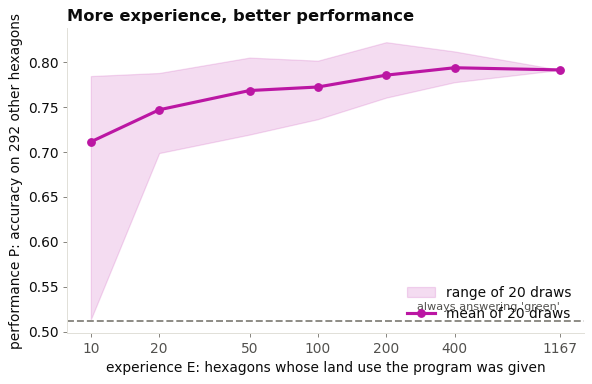

In [9]:
rest, held = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)      # 292 hexagons are set aside to measure the performance
sizes = [10, 20, 50, 100, 200, 400, len(rest)]
rows = []
for n_known in sizes:
    for draw in range(20):
        known = np.random.default_rng(draw).choice(rest, n_known, replace=False)
        if len(np.unique(y[known])) < 2:        # a draw with one land use only has nothing to tell apart
            continue
        model = LogisticRegression(max_iter=3000).fit(X[known], y[known])
        rows.append({"experience": n_known, "performance": model.score(X[held], y[held])})
learning = pd.DataFrame(rows).groupby("experience")["performance"].agg(["mean", "min", "max"])
print(learning.round(2).to_string())
h.note("learning", {int(k): round(float(v), 2) for k, v in learning["mean"].items()}, SAVE)

fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.fill_between(learning.index, learning["min"], learning["max"], color=h.ACCENT, alpha=0.15, label="range of 20 draws")
ax.plot(learning.index, learning["mean"], "o-", color=h.ACCENT, lw=2.5, label="mean of 20 draws")
ax.axhline((y == "green").mean(), color=h.MUTED, ls="--", lw=1.5)
ax.text(sizes[-1], (y == "green").mean() + 0.012, "always answering 'green'", ha="right", fontsize=9, color=h.SECONDARY)
ax.set_xscale("log")
ax.set_xticks(sizes, [str(s) for s in sizes])
ax.minorticks_off()
ax.set_xlabel("experience E: hexagons whose land use the program was given")
ax.set_ylabel("performance P: accuracy on 292 other hexagons")
ax.set_title("More experience, better performance")
ax.legend(loc="lower right")
plt.show()

> **What did we just see?** With 10 hexagons the program gets 71% of the other hexagons right on average, and between 51% and 78% depending on which 10 it was given. With 200 hexagons it gets 79%, and the result hardly depends on the draw any more. The performance rose with the experience, so by Mitchell's definition the program learned.
>
> The figure shows two more things. The curve is flat after about 200 hexagons: this simple model cannot use more examples, and the page on supervised learning shows what limits it. And a program that always answers `green` is right for 51% of the hexagons without learning anything, so an accuracy has to be read against that figure.

## Five ways to learn

Part 1 named five ways of learning. They differ in what the learner is given, and each has its page on this site.

| Way of learning | What the learner is given | On our hexagons | Page |
|---|---|---|---|
| Unsupervised | no answers at all | group the hexagons by their counts | [Unsupervised learning](unsupervised) |
| Supervised | an answer for every row | predict land use, or built-up land | [Supervised learning](supervised) |
| Semi-supervised | an answer for a few rows | 30 labels, 1,429 hexagons without | [Semi-supervised learning](semi_supervised) |
| Self-supervised | no answers; a part of the data is hidden and predicted | predict the neighbours of a hexagon from its own counts | [Self-supervised learning](self_supervised) |
| Reinforcement | no table; points for what it does | a courier robot on a grid of streets | [Reinforcement learning](reinforcement) |